# 2. Water: Getting Started

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/021-SmallMolecules.ipynb)
:::

What can we explore with computational chemistry? Let us **explore the electronic structure** of some small molecules. In this chapter we will learn ways to describe molecules to *Psi4* using *Python* code, run calculations from a *Jupyter* notebook, and interpret the results, both as *Python* variables and in the **output files** that *Psi4* writes.

## Learning Goals

This exercise will hopefully accomplish the following goals while learning new skills:
-	We will confirm that your installation of *Psi4* is **working properly**.
-	We will **construct** a molecule for *Psi4* using a few lines of *Python*.
-	We will use three methods for creating a description of the **atomic positions**
    -	Cartesian coordinates (classic *xyz* 3D space)
    -	Cartesian coordinates with **symmetry** detected by *Psi4*
    -	Internal coordinates using a *Z-matrix* (with variables and **dummy atoms**)
-	We will use *Psi4* to determine the **optimized structure** of small molecules using the HF/6-31G level of theory.
-	We will **look** at our molecules before and after optimization with *py3Dmol* and **plot** the energy at each step of the optimization.
-	We will humbly recognize that we are organic chemists and that we are using *Psi4* as a **recipe** with poor understanding of the **consequences** of our choices. We will observe these consequences in our results as we move forward. If we knew what we were doing, we might avoid many inevitable **pitfalls**. We have a whole box of band aids and always wear our safety goggles. Let's go!

## Small Molecules

**Methane**, **ammonia** and **water**: these three molecules are *sp<sup>3</sup>* hybridized and should be **tetrahedral** in their VSEPR geometry. We expect to see bonds or lone pairs at angles near 109&deg;.

To investigate these molecules, we will need to **describe** a molecule for a computer. We will discuss three methods: **Cartesian coordinates**, where every atom is placed in 3D space with *xyz* values; Cartesian coordinates where *Psi4* **detects the symmetry point group** and uses it to simplify the work; and the ***Z-matrix***, where each atom is placed in space relative to the previous ones in a carefully created list.

*Psi4* works by positioning the nuclei and then creating a mathematical function for the **energy** of the electrons. By taking the **derivative** of that function (the **gradient**), *Psi4* can determine if the current position is on a **slope** and then change the positions by a small amount to follow that slope downhill in energy. A new function is calculated and the process repeats again and again until the slope is (nearly) zero. This is a **geometry optimization**.

In this exercise, we will be **manually** typing in our molecules. In the future, we will learn how to use *Avogadro* to quickly build molecules and **automatically** create the coordinates. But let us first get our hands dirty before we start using power tools to do the hard work for us. Wax on, wax off!

In [ ]:
# Setup: imports, and installation of Psi4 when running on Google Colab.
# This cell is hidden in the web book (tag: remove-cell).
import os
import sys
import shutil
import subprocess
import urllib.request

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # 1. Colab has no conda. condacolab installs it and then RESTARTS the session.
    if shutil.which("conda") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "condacolab"], check=True)
        import condacolab
        print("Installing conda. The session will restart. Then run this cell again.")
        condacolab.install()

    # 2. Install Psi4 and py3Dmol with conda (only needed the first time).
    try:
        import psi4
    except ImportError:
        installer = shutil.which("mamba") or "conda"
        subprocess.run([installer, "install", "-y", "-q", "-c", "conda-forge",
                        "psi4", "py3dmol"], check=True)

    # 3. Download the plot style sheets from the book's GitHub repository.
    url = "https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/"
    os.makedirs("styles", exist_ok=True)
    for name in ["tufte.mplstyle", "S2_classic2.mplstyle"]:
        urllib.request.urlretrieve(url + name, os.path.join("styles", name))
    STYLE_DIR = "styles"
else:
    STYLE_DIR = "../styles"

import psi4
import py3Dmol
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use(os.path.join(STYLE_DIR, "tufte.mplstyle"))

## Setting Up the Notebook

Every *Psi4* notebook begins the same way. We **import** the *Python* packages that we need and tell *Psi4* how much of the computer it may use.

The imports are in the **first code cell** of the notebook. It is hidden on this web page, but you will see it when you open the notebook in *Jupyter*, *Visual Studio Code* or *Google Colab*. It loads these packages...

| Package | What it does |
| :---- | :---- |
| `import psi4` | Loads *Psi4*. Everything *Psi4* can do is now available as `psi4.something`. |
| `import py3Dmol` | Loads the 3-D molecule **viewer**. |
| `import numpy as np` | *NumPy* does the **math** on arrays of numbers (like a list of atomic coordinates). |
| `import pandas as pd` | *Pandas* makes **tables** of data. |
| `import matplotlib.pyplot as plt` | *Matplotlib* makes **plots**. |

It also applies the **style sheet** used for all the plots in this book.

```{admonition} Running this notebook in Google Colab
:class: dropdown
The first code cell checks whether the notebook is running in *Google Colab*. If it is, the cell **installs** *Psi4* for you. *Colab* does not come with *conda*, so the cell first installs it using a package called *condacolab*. This **restarts** the *Colab* session. When it has restarted, simply **run the first cell again**. It will then install *Psi4* and *py3Dmol* with *conda* and download the plot style sheets from the book's *GitHub* repository. This takes a few minutes, and you must do it every time you start a new *Colab* session. On your own computer, the cell just imports the packages.
```

Next, we tell *Psi4* how much of the computer it may use.

In [1]:
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

psi4.set_options({"scf_type": "pk"})


  Memory set to   3.725 GiB by Python driver.
  Threads set to 4 by Python driver.


| Line | Notes |
| :---- | :---- |
| `psi4.set_memory("4 GB")` | The **memory** *Psi4* may use. Increase this if a big job complains about a lack of memory. *Psi4* reports this as `3.725 GiB`. It is the same amount of memory, counted in units of 1024&sup3; bytes rather than 1000&sup3; bytes. |
| `psi4.set_num_threads(4)` | The number of **processor cores** *Psi4* may use at once. |
| `psi4.set_options({"scf_type": "pk"})` | *Psi4* normally uses a shortcut called **density fitting** to speed up the calculation of electron repulsion. `pk` tells it to calculate those integrals **exactly**. Our molecules are tiny so the cost is trivial. |

The `psi4.set_options()` function takes a *Python* **dictionary** of `{"option": value}` pairs. It is the *Psi4* equivalent of all those groups of settings in an old-fashioned input file. We will add more options in later chapters.

### Some Helpful Tools

We will do a few things **over and over** in this chapter: look at a molecule, measure bond lengths and angles, plot the energy at each optimization step, and search the output file for interesting lines. Rather than typing the same code many times, we will define **four small functions** now and use them throughout. Run the cell below once. Nothing visible happens, but the functions are now ready to use.

In [2]:
def show_molecule(mol):
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def bond_length(mol, i, j):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    return np.linalg.norm(xyz[i] - xyz[j])

def bond_angle(mol, i, j, k):
    xyz = mol.geometry().np
    a = xyz[i] - xyz[j]
    b = xyz[k] - xyz[j]
    cos_angle = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(cos_angle))

def plot_history(history, title):
    energies = np.array(history["energy"])
    delta_E = (energies - energies[-1]) * psi4.constants.hartree2kJmol
    steps = np.arange(1, len(energies) + 1)

    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
    ax.plot(steps, delta_E, color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
    ax.set_xticks(steps)
    ax.set_xlabel("Optimization step")
    ax.set_ylabel(r"$E - E_{final}$ (kJ/mol)")
    ax.set_title(title)
    plt.show()

def search_file(filename, text):
    with open(filename) as f:
        for number, line in enumerate(f, start=1):
            if text.lower() in line.lower():
                print(f"{number:6d}: {line.rstrip()}")

| Function | What it does |
| :---- | :---- |
| `show_molecule(mol)` | Makes a *py3Dmol* **viewer** 400 &times; 300 pixels in size, gives it the molecule as text in *xyz* format (`mol.save_string_xyz_file()`), draws the atoms as **sticks** with small **spheres**, sets a very light gray **background** (`#f2f2f2`), zooms to fit and shows it. You can rotate the molecule with your mouse. |
| `bond_length(mol, i, j)` | Gets the **coordinates** of all atoms (`mol.geometry().np`) and converts them from *Psi4*'s internal **Bohr** units to **&Aring;ngstroms**. The distance between atom `i` and atom `j` is the length (`norm`) of the vector between them. |
| `bond_angle(mol, i, j, k)` | Makes two vectors pointing from the **central** atom `j` to atoms `i` and `k`. The cosine of the angle between two vectors is their **dot product** divided by their lengths. `arccos` gives the angle in radians, and `degrees` converts it. |
| `plot_history(history, title)` | Takes the list of **energies** from each step of an optimization, subtracts the final energy and converts to *kJ/mol*, then **plots** them against the step number. |
| `search_file(filename, text)` | Opens a text file and **prints** every line (with its line number) that contains `text`. This is our *Python* version of using the "find" command in a text editor. |

```{note}
*Python* counts from **zero**. The first atom in a molecule is atom `0`, the second is atom `1`, and so on. This is different from the atom numbers in a *Z-matrix*, which count from **one**. You will get this wrong at least once. Everybody does.
```

## Water

Water has three atoms that have found an **arrangement** in space for the nuclei and electrons that is as **low in energy** as possible. Can we calculate that arrangement and see if it fits with observations? First, we must create a data set that describes the positions of the nuclei. Let us begin by discussing the **coordinate space** used by *Psi4*.

### The 3D World

*x*, *y*, *z*... That triplet describes the **entire universe**. When we give *Psi4* a set of Cartesian coordinates, we may place the molecule anywhere we like. *Psi4* will then **move** the molecule so that its **center of mass** is at the origin and **rotate** it into a standard orientation that suits its symmetry. You can stop this behaviour by adding the words `no_com` and `no_reorient` to the molecule description, but we will rarely want to.

### Symmetry

Symmetry is beautiful. It also helps with math. If a molecule has symmetry, the calculation can be **less expensive**. A molecule that is known to possess 2-fold symmetry may be half as difficult to analyze because we may only need half the math.

**Water** has a *C<sub>2</sub>* axis. There is no perpendicular *C<sub>2</sub>* axis so we remain in the *C* group rather than rising to *D*. There is no *&sigma;<sub>h</sub>* but there are two *&sigma;<sub>v</sub>* planes. Therefore water is in the *C<sub>2v</sub>* point group. We will place the **primary axis** along the *z*-axis and the atoms in the *xz* plane. See {numref}`fig-water-axes`.

```{figure} ../images/WATER_AXES.png
---
width: 500px
name: fig-water-axes
---
*Water positioned in 3D space with the C<sub>2</sub> axis along the z-axis and the atoms in the xz plane.*
```

Older programs such as *GAMESS* make you **declare** the point group and enter only the **symmetry-unique** atoms. *Psi4* is friendlier. We give it **all** the atoms and it **detects** the point group by itself. If the structure is close to a symmetrical one (within a small tolerance), *Psi4* will also **symmetrize** it, nudging the atoms into exactly symmetrical positions.

There is a catch. *Psi4* only does its math in the point group *D<sub>2h</sub>* and its **subgroups** (*C<sub>1</sub>*, *C<sub>i</sub>*, *C<sub>s</sub>*, *C<sub>2</sub>*, *C<sub>2v</sub>*, *C<sub>2h</sub>*, *D<sub>2</sub>* and *D<sub>2h</sub>*). These are the "Abelian" point groups, where the symmetry operations behave nicely with each other. Water is *C<sub>2v</sub>*, so *Psi4* can use all of its symmetry. Ammonia is *C<sub>3v</sub>*, so *Psi4* will do its math in *C<sub>s</sub>*, the largest subgroup that it can use. *Psi4* will report both the **full** point group and the **computational** point group.

### Building Water

So how shall we build water? We can provide Cartesian coordinates that position **oxygen** at the origin. Then we can position a **hydrogen** in one *xz* quadrant and the second hydrogen in the opposite quadrant. Compare the coordinates below to {numref}`fig-water-axes`.

| Atom	   |   x   | y     | z     |
|:-----    | :---: | :---: | :---: |
| Oxygen   | 0	   | 0	   | 0     |
| Hydrogen | b	   | 0	   | &ndash;a    |
| Hydrogen | &ndash;b    | 0     | &ndash;a    |

What values should we use for *a* and *b*? We know that the **bond angle** should be about 104.5&deg; and that the **bond length** in water is about 0.96 &Aring;. We could use trigonometry and position the atoms accordingly. Or we could just throw in a **guess** and let *Psi4* start there as it moves toward the optimal structure. I will set both *a* and *b* to 0.7 &Aring;. Our initial guess at water will have a bond angle of 90&deg; and a bond length of $\sqrt{0.7^2+0.7^2} = 0.99$ &Aring;.

### Your First Molecule

In *Psi4* the molecule is described in a block of **text** that we hand to the `psi4.geometry()` function. In *Python*, text surrounded by triple quotes (`"""`) can run over many lines.

In [3]:
water = psi4.geometry("""
0 1
O    0.0   0.0   0.0
H    0.7   0.0  -0.7
H   -0.7   0.0  -0.7
""")

water.update_geometry()
show_molecule(water)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `water = psi4.geometry("""` | Creates a *Psi4* **molecule** object from the text that follows and gives it the name `water`. |
| `0 1` | The **charge** on the molecule (0) and the spin **multiplicity** (1 means all electron spins are paired). If you leave this line out, *Psi4* will assume a neutral molecule with the lowest reasonable multiplicity. |
| `O 0.0 0.0 0.0` | Each following line is an **atom**: the element symbol and then the *x*, *y* and *z* coordinates. The default unit is the **&Aring;ngstrom**. |
| `""")` | Ends the text and the function call. |
| `water.update_geometry()` | *Psi4* is lazy. It does not actually process the text until it needs to. This line tells it to do so **now**: build the Cartesian coordinates, move the center of mass to the origin, reorient the molecule and **detect the symmetry**. |
| `show_molecule(water)` | Draws our **starting** structure. |

Above you should see our guess at water. It looks a little squashed with its 90&deg; bond angle. Let us ask *Psi4* what it thinks of our molecule before we do anything else.

In [4]:
print("Full point group:         ", water.get_full_point_group())
print("Computational point group:", water.schoenflies_symbol())
print(f"Starting O-H length: {bond_length(water, 0, 1):.4f} Angstrom")
print(f"Starting H-O-H angle: {bond_angle(water, 1, 0, 2):.2f} degrees")

Full point group:          C2v
Computational point group: c2v
Starting O-H length: 0.9899 Angstrom
Starting H-O-H angle: 90.00 degrees


*Psi4* found the *C<sub>2v</sub>* point group without being told, and our measuring functions confirm the starting bond length of 0.99 &Aring; and angle of 90&deg;. Atom `0` is the oxygen and atoms `1` and `2` are the hydrogens, in the order that we typed them.

-----

## Your First *Psi4* Job

Now we have a **molecule**. We need to tell *Psi4* what **kind** of calculation to do and what **method** to use for determining the energy. We will perform a **geometry optimization** using Hartree-Fock theory with the 6-31G basis set (HF/6-31G).

In [5]:
psi4.set_output_file("water_cart.out", False)

E_water, hist_water = psi4.optimize("hf/6-31g", molecule=water, return_history=True)

print(f"Final energy: {E_water:.8f} Hartree")

Optimizer: Optimization complete!
Final energy: -75.98535917 Hartree


| Line | Notes |
| :---- | :---- |
| `psi4.set_output_file("water_cart.out", False)` | All the details of the calculation will be written to a **text file** named `water_cart.out` in the same folder as this notebook. `False` means that the file is **replaced** rather than added to if it already exists. |
| `psi4.optimize(...)` | Runs a **geometry optimization**. Use `psi4.energy()` instead if you only want the energy of a structure as it stands (a "single point" calculation). |
| `"hf/6-31g"` | The **method** / **basis set**. `hf` is Hartree-Fock theory. Since water has all its electrons paired, *Psi4* uses **restricted** Hartree-Fock (RHF) automatically. `6-31g` is the basis set used to describe the atomic orbitals. |
| `molecule=water` | Which molecule to optimize. |
| `return_history=True` | Asks *Psi4* to also give us a record (the **history**) of the energy and coordinates at every step of the optimization. We will use it to make a plot. |
| `E_water, hist_water = ` | `psi4.optimize()` returns **two things** here: the final energy (a number, in Hartrees) and the history (a dictionary of lists). We store them in two variables. |

In a few seconds the job is finished. That's all there is to it. The molecule object `water` has been **updated** and now holds the optimized structure.

```{tip}
A file called `timer.dat` and some files ending in `.clean` or `.log` may also appear in your folder. You can ignore them.
```

### Results from *Python*

Because *Psi4* lives inside *Python*, the results are **variables** that we can use right away. Let us measure the optimized molecule.

In [6]:
print(f"Energy:      {E_water:.8f} Hartree")
print(f"O-H lengths: {bond_length(water, 0, 1):.4f}  {bond_length(water, 0, 2):.4f} Angstrom")
print(f"H-O-H angle: {bond_angle(water, 1, 0, 2):.2f} degrees")
print("Steps taken:", len(hist_water["energy"]))

show_molecule(water)

Energy:      -75.98535917 Hartree
O-H lengths: 0.9496  0.9496 Angstrom
H-O-H angle: 111.55 degrees
Steps taken: 5


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

We now have the **energy** (&minus;75.98536 Hartree) and the **structure** for the final step of the optimization, which *Psi4* reached after **five** steps. The two **bond lengths** are identical (0.950 &Aring;), as required by the *C<sub>2v</sub>* point group. The bond angle has opened up from our squashed 90&deg; guess to 111.5&deg;, **larger** than the tetrahedral angle. Compare these with the experimental structure of water: an O&ndash;H bond length of 0.958 &Aring; and an H&ndash;O&ndash;H angle of 104.5&deg;. The bond length is close (0.008 &Aring; too short). The bond angle is **too large** by 7&deg;. We will discuss why below.

### Energy at Each Step

The `hist_water` dictionary holds the energy at each step of the optimization. Let us plot it.

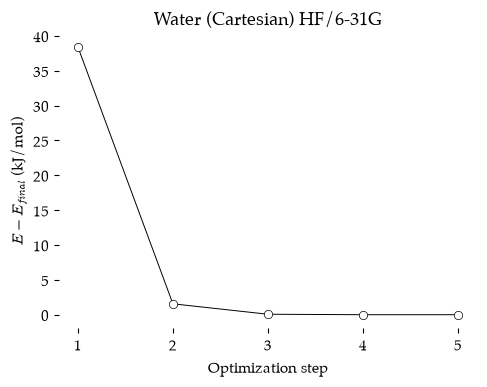

In [7]:
plot_history(hist_water, "Water (Cartesian) HF/6-31G")

The energy drops **steeply** in the first step as the squashed molecule relaxes, then **levels off** as the structure approaches the bottom of the energy well. Our starting guess was 38 *kJ/mol* above the final structure. After one step, only 1.6 *kJ/mol* remained. The last few steps change the energy by tiny amounts. The plot shows energies **relative** to the final energy in *kJ/mol*, so the last point is always zero. You can see the actual numbers with `print(hist_water["energy"])`.

-----

## Your First Output File

The *Python* variables give us the **important** results. The output file `water_cart.out` gives us **everything**. You can open it in *Visual Studio Code* or any **text editor**. It is long. Rather than scroll through it, we can **search** it for interesting lines with our `search_file()` function.

### The Starting Structure

Near the top of the file, *Psi4* reports the molecule it **received**, after moving the center of mass to the origin and detecting the symmetry.

In [8]:
search_file("water_cart.out", "point group")

    80:     Molecular point group: c2v
    81:     Full point group: C2v
   265:     Molecular point group: c2v
   266:     Full point group: C2v
   374:     Molecular point group: c2v
   375:     Full point group: C2v
   415:     Molecular point group: c2v
   416:     Full point group: C2v
   609:     Molecular point group: c2v
   610:     Full point group: C2v
   718:     Molecular point group: c2v
   719:     Full point group: C2v
   759:     Molecular point group: c2v
   760:     Full point group: C2v
   952:     Molecular point group: c2v
   953:     Full point group: C2v
  1061:     Molecular point group: c2v
  1062:     Full point group: C2v
  1102:     Molecular point group: c2v
  1103:     Full point group: C2v
  1295:     Molecular point group: c2v
  1296:     Full point group: C2v
  1404:     Molecular point group: c2v
  1405:     Full point group: C2v
  1445:     Molecular point group: c2v
  1446:     Full point group: C2v
  1637:     Molecular point group: c2v
  1638:     

*Psi4* prints the **point group** it is using several times during each step: when it sets up the step, and again when it calculates the energy and the gradient. You will see `c2v` (the **computational** point group, in lower case) and `C2v` (the **full** point group) three times for each of our five steps.

Let us look at the starting **geometry** that *Psi4* used. The lines below print the first block of coordinates in the file. Compare them with the coordinates that we typed.

In [9]:
with open("water_cart.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Geometry (in Angstrom)" in line)
print("".join(lines[start:start + 8]))

    Geometry (in Angstrom), charge = 0, multiplicity = 1:

       Center              X                  Y                   Z               Mass       
    ------------   -----------------  -----------------  -----------------  -----------------
         O            0.000000000000     0.000000000000     0.078340411302    15.994914619570
         H            0.700000000000     0.000000000000    -0.621659588698     1.007825032230
         H           -0.700000000000    -0.000000000000    -0.621659588698     1.007825032230




| Line | Notes |
| :---- | :---- |
| `lines = f.readlines()` | Reads the whole file into a *Python* **list**, one item per line. |
| `next(i for i, line in ...)` | Finds the number of the **first** line that contains the words `Geometry (in Angstrom)`. |
| `lines[start:start + 8]` | Takes that line and the seven after it. `"".join(...)` glues them back together for printing. |

These are **not quite** the coordinates that we typed. The *x* and *y* values are the same, but every *z* value has been shifted by +0.0783 &Aring;. *Psi4* has moved the molecule so that its **center of mass** is at the origin. The heavy oxygen now sits just above the origin and the light hydrogens sit farther below it. Our water was already lined up with its *C<sub>2</sub>* axis along *z* and its atoms in the *xz* plane, so *Psi4* did not need to **rotate** it. (*GAMESS* made exactly the same shift of 0.0783 &Aring; with this starting structure. The center of mass is the center of mass in any program.)

### The Energy at Each Step

Every time *Psi4* finishes a **self-consistent field** (SCF) calculation for a structure, it prints a line beginning with `@RHF Final Energy`. Search for it.

In [10]:
search_file("water_cart.out", "@RHF Final Energy")

   212:   @RHF Final Energy:   -75.97072390420961
   556:   @RHF Final Energy:   -75.98476349862631
   899:   @RHF Final Energy:   -75.98533329721914
  1242:   @RHF Final Energy:   -75.98535888514650
  1584:   @RHF Final Energy:   -75.98535917322789


There is one line for each **step** of the optimization. The initial energy and the derivative (the **gradient** of the energy with respect to the position of each atom) was calculated for our starting structure. The gradient was used to compute a distance to **move** each atom, the move was applied, and the energy was calculated **again**. Watch the energy fall with each step. These are the same numbers that we plotted from `hist_water`. Our water started at &minus;75.97072 Hartree and finished at &minus;75.98536 Hartree after five steps. Almost all of the drop (0.0140 Hartree, or 37 *kJ/mol*) happened in the **first** step. The last step changed the energy by less than 0.000001 Hartree.

### The Convergence Checks

At **every step**, *Psi4*'s optimizer (called *optking*) prints a **convergence check**. This is a small table that compares the current step with the criteria for declaring that we have reached the bottom of the energy well. Each line of these tables ends with a `~` character so that it is easy to find.

In [11]:
search_file("water_cart.out", "~")

   357: 	----------------------------------------------------------------------------------------------~
   358: 	   Step    Total Energy     Delta E     Max Force     RMS Force      Max Disp      RMS Disp   ~
   359: 	----------------------------------------------------------------------------------------------~
   360: 	  Convergence Criteria     1.00e-06 *    3.00e-04 *             o    1.20e-03 *             o~
   361: 	----------------------------------------------------------------------------------------------~
   362: 	     1     -75.97072390   -7.60e+01      7.03e-02      4.46e-02 o    3.74e-01      2.19e-01 o  ~
   706: 	     2     -75.98476350   -1.40e-02      1.79e-02      1.47e-02 o    3.94e-02      3.24e-02 o  ~
  1049: 	     3     -75.98533330   -5.70e-04      3.87e-03      3.16e-03 o    7.43e-03      6.40e-03 o  ~
  1392: 	     4     -75.98535889   -2.56e-05      3.96e-04      3.24e-04 o    7.87e-04 *    7.13e-04 o  ~
  1734: 	     5     -75.98535917   -2.88e-07 *    4.

The search found the **header** of the table once (lines 357 to 361) and then one line for **each step** of the optimization. Here is what we found for water.

```text
 ----------------------------------------------------------------------------------------------~
    Step    Total Energy     Delta E     Max Force     RMS Force      Max Disp      RMS Disp   ~
 ----------------------------------------------------------------------------------------------~
   Convergence Criteria     1.00e-06 *    3.00e-04 *             o    1.20e-03 *             o~
 ----------------------------------------------------------------------------------------------~
      1     -75.97072390   -7.60e+01      7.03e-02      4.46e-02 o    3.74e-01      2.19e-01 o  ~
      2     -75.98476350   -1.40e-02      1.79e-02      1.47e-02 o    3.94e-02      3.24e-02 o  ~
      3     -75.98533330   -5.70e-04      3.87e-03      3.16e-03 o    7.43e-03      6.40e-03 o  ~
      4     -75.98535889   -2.56e-05      3.96e-04      3.24e-04 o    7.87e-04 *    7.13e-04 o  ~
      5     -75.98535917   -2.88e-07 *    4.26e-05 *    3.48e-05 o    8.21e-05 *    6.95e-05 o  ~
```

| Column | Notes |
| :---- | :---- |
| `Step` | The **step** number of the optimization. |
| `Total Energy` | The **energy** at that step, in Hartrees. |
| `Delta E` | The **change** in energy from the previous step. For step 1 there is no previous step, so it is just the energy. |
| `Max Force`, `RMS Force` | The largest and the average (root-mean-square) **forces** on the atoms. Force is the slope of the energy surface. At the bottom of the well, the force should be close to zero. |
| `Max Disp`, `RMS Disp` | The largest and the average **distances** that the atoms were moved in that step. |
| `Convergence Criteria` | The **targets**. A `*` marks a criterion that is in use, and a `*` beside a step's value means that target has been met. An `o` marks a criterion that is not in use. |

*Psi4* declares that it has found a **stationary point** when all the criteria in use have been met. By default these are the change in energy (below 1.0 &times; 10<sup>&minus;6</sup> Hartree), the largest force (below 3.0 &times; 10<sup>&minus;4</sup>) and the largest displacement (below 1.2 &times; 10<sup>&minus;3</sup>). The RMS values are not used (marked `o`). Watch the `*` marks appear as the optimization proceeds. At step 4, only the displacement was small enough. At step 5, all three targets were met and the optimization was **complete**. These are the same ideas as the `OPTTOL` gradient criterion in *GAMESS*. The default criteria are fine for our work.

### The Final Structure

After the summary, *Psi4* prints the final **optimized geometry**.

In [12]:
start = next(i for i, line in enumerate(lines) if "Final optimized geometry" in line)
print("".join(lines[start:start + 10]))

    Final optimized geometry and variables:
    Molecular point group: c2v
    Full point group: C2v

    Geometry (in Angstrom), charge = 0, multiplicity = 1:

    O            0.000000000000     0.000000000000     0.059775301187
    H            0.785140594701     0.000000000000    -0.474338703779
    H           -0.785140594701    -0.000000000000    -0.474338703779




These are the coordinates of the **optimized** water molecule. It is still in the *xz* plane with the oxygen on the *z*-axis and the center of mass at the origin. Compare the hydrogen positions with our starting guess. Relative to the oxygen, each hydrogen has moved **outward** (*x* from 0.700 to 0.785 &Aring;) and **upward** (from 0.700 to 0.534 &Aring; below the oxygen). This opens the bond angle and shortens the bonds. We could copy these coordinates into a new molecule for another calculation, but there is no need. The `water` molecule object in our notebook already **holds** them.

-----

## Levels of Theory

What is this HF/6-31G that we keep typing? Every calculation requires two **choices**. The **method** is the theory used to describe how the electrons interact. The **basis set** is the collection of mathematical functions used to build the atomic orbitals. Together, the method and the basis set are called the **level of theory**.

**Hartree-Fock** (HF) theory is the foundation of *ab initio* ("from the beginning") quantum chemistry. It makes no use of experimental data. It treats each electron as moving in the **average** field of all the other electrons. This ignores the way that electrons dodge each other from moment to moment (**electron correlation**). The Restricted Hartree-Fock (RHF) method that we are using also enforces that all electrons are **paired** in molecular orbitals.

The **6-31G** basis set describes each atomic orbital using combinations of **Gaussian functions**. Gaussian functions are far easier for a computer to calculate than the "real" shapes of atomic orbitals, and adding many Gaussians together can get very close to the real answer. In 6-31G, each core orbital is made of 6 Gaussians, and each valence orbital is split into two parts made of 3 Gaussians and 1 Gaussian. More Gaussians, and more ways of combining them, will give better accuracy but will also be more expensive in computer time.

```{note}
Don't think about it too much. HF/6-31G is nowhere near the state of the art, but it will serve for what we need to do. To understand the theory and the choice of basis sets you should enjoy the **computational chemistry course** that is taking place in parallel with this course. We will use *Psi4* without having a clue what we are doing. Lives are not at stake here.
```

### There Are Better Methods

There are **many more accurate** levels of theory available in *Psi4*, and using them is as easy as changing the text in `psi4.optimize()`. For example...

| Level of theory | What changes |
| :---- | :---- |
| `"hf/6-31g(d,p)"` | Adds **polarization** functions (*d* orbitals on heavy atoms and *p* orbitals on hydrogen) so the electron density can bend away from the atoms. This fixes much of the bond angle problem in water and ammonia. |
| `"hf/6-311++g(d,p)"` | A larger basis set with **diffuse** functions (`++`) for electron density far from the nucleus, as in anions and lone pairs. |
| `"b3lyp/6-31g(d)"` | **Density functional theory** (DFT). Includes an approximate treatment of electron correlation at a cost similar to HF. Very popular. |
| `"mp2/cc-pvtz"` | Second-order **perturbation theory** adds electron correlation. More expensive. |
| `"ccsd(t)/cc-pvtz"` | **Coupled cluster** theory, the "gold standard" for small molecules. Very expensive. The cost rises steeply with the size of the molecule. |

Better methods cost more. The cost of HF rises roughly with the **fourth power** of the size of the basis set. The cost of CCSD(T) rises with the **seventh** power. Double the size of the molecule and a CCSD(T) calculation may take more than 100 times longer.

### Why Use a Low Level of Theory?

If better methods are available, why use HF/6-31G at all? Because, for organic chemists, a cheap calculation is often **good enough** to answer the question we are asking.

- **Shapes and trends are robust.** HF/6-31G will tell you that water is bent, that ammonia is pyramidal, that butane prefers the *anti* conformation and that benzene is flat. The exact numbers may be off by a few percent, but the **qualitative** picture, the thing that VSEPR theory and our chemical intuition predict, is usually correct.
- **Comparisons cancel errors.** We are usually interested in **differences** in energy (between conformers, or between a reactant and a transition state). The errors of a given level of theory tend to be similar for similar structures, so they partly **cancel** when we subtract.
- **Molecular orbitals look the same.** The shapes and ordering of the frontier molecular orbitals that we use to explain reactivity are well described by HF theory.
- **Cheap structures are good starting points.** The geometry from a cheap optimization is usually very close to the geometry from an expensive one. We can optimize the structure at a low level and then calculate a single-point energy at a high level using that structure. Or we can use the cheap structure as the **starting point** for an expensive optimization so that it needs only a few steps. We stand on the shoulders of giants.
- **We can afford to explore.** A calculation that takes one second lets us try many ideas, make many mistakes and **learn** from them. A calculation that takes a day does not.

In this book we will use HF/6-31G for nearly everything. Where it matters, we will check our results with a **higher** level of theory.

```{note}
In general, a calculated HF energy is always **higher** than the "true" energy. Only a perfect basis set that includes an exact model for the atomic orbitals will give the lowest value possible for the method. Nothing is perfect, but we can get close if we take the time to run more expensive methods and basis sets.
```

## Units

Hartrees? You may notice that the output file reports energy in **Hartree units**, and distances in both **&Aring;ngstroms** and **Bohr** atomic units. Deep inside *Psi4*, the math uses Bohr for distance, along with the elementary charge, the mass of the electron and Planck's constant. The Hartree is an energy unit derived from these **fundamental** properties of the hydrogen atom.

**Keep** this conversion factor close by: 1 Hartree = 2625.5 *kJ/mol*.

One Hartree is 4.3597 &times; 10<sup>&minus;18</sup> *J*. When we multiply by Avogadro's number we get 2625.5 *kJ/mol*. *Psi4* stores this and other conversion factors for us in `psi4.constants`.

In [13]:
print(psi4.constants.hartree2kJmol)
print(psi4.constants.bohr2angstroms)

2625.4996382852164
0.52917721067


## Internal Coordinates

For many of our exercises, we will be building molecules using **internal coordinates**. These coordinates define atomic positions **relative** to atoms that have already been placed. A ***Z-matrix*** is a defined format for listing these internal coordinates.

Imagine three towns in a flat prairie, the last three towns on Earth. If I start at town A and travel 10 miles to town B, turn 45&deg; left and travel 5 miles to town C, then I can place the towns exactly, relative to each other. I will know the distance between A and C and all other angles from those first three coordinates.

Here is a *Z-matrix* for our town map...

```text
A
B  1  10
C  2   5  1  45
```

It can be interpreted as...

| Line | Notes |
| :---- | :---- |
|  1 |	Town A is declared to **exist**. |
|  2 |	Town B is connected to line 1 by a **distance** of 10 miles. |
|  3 |	Town C is connected to line 2 by a **distance** of 5 miles \& the **angle** through line 2 to line 1 is 45&deg;. |

### The *Z-matrix* with Water

Here is a *Z-matrix* for the molecule water. It is interpreted in {numref}`fig-zmatrix`.

```text
H
O  1  1.0
H  2  1.0  1  109.5
```

```{figure} ../images/Zmatrix.png
---
width: 500px
name: fig-zmatrix
---
*Parsing the Z-matrix for water.*
```

For a molecule to have *C<sub>2v</sub>* symmetry, the two O&ndash;H bond lengths **must** be the same. One way that we can make sure that this is true is to use **variables** in the *Z-matrix*. Below, the bond length is given the name `r` and the bond angle the name `a`. The values of the variables are given at the **end** of the molecule description. Both bonds use the same variable, so they are guaranteed to be identical.

In [14]:
water_z = psi4.geometry("""
0 1
H
O  1  r
H  2  r  1  a

r = 1.0
a = 109.5
""")

water_z.update_geometry()
print("Full point group:", water_z.get_full_point_group())
show_molecule(water_z)

Full point group: C2v


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `H` | Atom 1 is a hydrogen. It is declared to **exist**. |
| `O 1 r` | Atom 2 is an oxygen, a distance `r` from atom 1. |
| `H 2 r 1 a` | Atom 3 is a hydrogen, a distance `r` from atom 2 (the oxygen), with an angle `a` through atom 2 to atom 1. |
| (blank line) | Separates the atoms from the variables. Not required, but it makes the text easier to read. |
| `r = 1.0`, `a = 109.5` | The **starting values** of the variables, in &Aring;ngstroms and degrees. |

*Psi4* uses the *Z-matrix* to create a set of Cartesian coordinates, moves the center of mass to the origin, reorients the molecule and detects the **symmetry**. Now let us optimize it.

Optimizer: Optimization complete!
Energy:      -75.98535917 Hartree
O-H length:  0.9497 Angstrom
H-O-H angle: 111.55 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

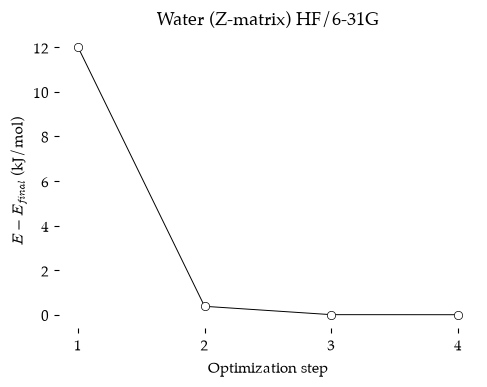

In [15]:
psi4.set_output_file("water_zmat.out", False)

E_water_z, hist_water_z = psi4.optimize("hf/6-31g", molecule=water_z, return_history=True)

print(f"Energy:      {E_water_z:.8f} Hartree")
print(f"O-H length:  {bond_length(water_z, 0, 1):.4f} Angstrom")
print(f"H-O-H angle: {bond_angle(water_z, 0, 1, 2):.2f} degrees")

show_molecule(water_z)
plot_history(hist_water_z, "Water (Z-matrix) HF/6-31G")

Note that the atom numbers in our measurements have **changed**. In this *Z-matrix* the oxygen is the **second** atom (atom `1` in *Python*), so the bond angle is measured as `bond_angle(water_z, 0, 1, 2)`.

The final energy (&minus;75.98535917 Hartree) and structure (0.9497 &Aring; and 111.55&deg;) are the **same** as for the Cartesian job, to within the convergence criteria. The molecule is the **same** no matter which coordinate system we use to describe it. The optimization took **four** steps rather than five, and the energy plot has a different shape, because we started from a **different** guess (a 109.5&deg; angle and a 1.0 &Aring; bond length rather than 90&deg; and 0.99 &Aring;). This guess was closer to the answer.

The *Z-matrix* is useful because we can **see** the bond lengths and angles directly in the result. When a molecule was built from a *Z-matrix*, *Psi4* reports the optimized **values of the variables** at the end of the output file.

In [16]:
with open("water_zmat.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Final optimized geometry" in line)
print("".join(lines[start:start + 12]))

    Final optimized geometry and variables:
    Molecular point group: c2v
    Full point group: C2v

    Geometry (in Angstrom), charge = 0, multiplicity = 1:

    H       
    O             1           r
    H             2           r      1           a

    a         =  111.5477090826
    r         =    0.9496726319



*Psi4* gives us back our *Z-matrix*, followed by the optimized values of the **variables**: `r = 0.9496726319` &Aring; and `a = 111.5477090826`&deg;. These are the optimized bond length and bond angle. They match the values from our `bond_length()` and `bond_angle()` functions. We did not need to use trigonometry to get the bond angle from *xyz* data. Our helper functions are nice, but the *Z-matrix* gives these numbers for **free**.

*Psi4* can also write a table of **all** the distances and angles in a molecule to the output file. This works for any molecule, however it was built.

In [17]:
water_z.print_distances()
water_z.print_bond_angles()

search_file("water_zmat.out", "Distance")
search_file("water_zmat.out", "Angle")

  1424:         Interatomic Distances (Angstroms)
  1426:         Distance 1 to 2 0.950
  1427:         Distance 1 to 3 1.570
  1428:         Distance 2 to 3 0.950
  1431:         Bond Angles (degrees)
  1433:         Angle 2-1-3:   34.226
  1434:         Angle 1-2-3:  111.548
  1435:         Angle 1-3-2:   34.226


`print_distances()` and `print_bond_angles()` **append** tables to the end of the current output file. We then searched the file for the lines that contain the words `Distance` and `Angle`. In these tables *Psi4* numbers the atoms from **one**, in the order of our *Z-matrix*: H is 1, O is 2 and H is 3.

- Distances 1 to 2 and 2 to 3 are the two O&ndash;H **bonds** (0.950 &Aring;). Distance 1 to 3 is between the two hydrogens (1.570 &Aring;). It is listed even though they are not bonded.
- Angle 1-2-3, with the oxygen in the **middle**, is the H&ndash;O&ndash;H bond angle (111.548&deg;). The other two angles (34.226&deg;) are the angles at the hydrogens in the triangle made by the three atoms. *Psi4* lists every combination of three atoms, whether it makes chemical sense or not. The three angles of the triangle add up to 180&deg;, as they must.

### The *Z-matrix* for Ammonia

Water is a planar system (for the atoms) but **ammonia** is going to require a **third dimension**. Here is one option for the *Z-matrix*.

```text
N
H   1   1.0
H   1   1.0   2   109.5
H   1   1.0   2   109.5   3   120
```

This describes the *Z-matrix* as shown parsed in {numref}`fig-zmatrix-ammonia`.

```{figure} ../images/Zmatrix_Ammonia.png
---
width: 500px
name: fig-zmatrix-ammonia
---
*A Z-matrix for ammonia.*
```

Although the *Z-matrix* will create a structure that looks a lot like ammonia, the three **bond angles** between H and N will not all be **exactly** identical. We defined the 3,1,2 and the 4,1,2 angles as 109.5&deg;. However we did not define the 4,1,3 bond angle. It will be the result of **positioning** the atoms according to the *Z-matrix* (1.0 &Aring; from the nitrogen, 109.5&deg; from the 2,1 bond and 120&deg; from the 1,2,3 plane). That third angle works out to about 109.44&deg;. Close, but **not exactly** the same, and so the structure is not an exact fit to *C<sub>3v</sub>* symmetry.

Older programs such as *GAMESS* will simply **refuse** to run this structure in the *C<sub>3v</sub>* point group. Let us see what *Psi4* does with it. We will not optimize this one. We just want to see how *Psi4* interprets it.

In [18]:
ammonia_naive = psi4.geometry("""
0 1
N
H   1   1.0
H   1   1.0   2   109.5
H   1   1.0   2   109.5   3   120.0
""")

ammonia_naive.update_geometry()
print("Full point group:         ", ammonia_naive.get_full_point_group())
print("Computational point group:", ammonia_naive.schoenflies_symbol())
print(f"H-N-H angles: {bond_angle(ammonia_naive, 1, 0, 2):.4f}",
      f"{bond_angle(ammonia_naive, 1, 0, 3):.4f}",
      f"{bond_angle(ammonia_naive, 2, 0, 3):.4f}")

Full point group:          Cs
Computational point group: cs
H-N-H angles: 109.5000 109.5000 109.4424


*Psi4* did not crash, but it did not find *C<sub>3v</sub>* symmetry either. It reported the full point group as *C<sub>s</sub>*. Two of the H&ndash;N&ndash;H angles are 109.5000&deg; and the third is 109.4424&deg;. The structure is only 0.06&deg; away from being symmetrical, but *Psi4* took us at our word. It kept the one **mirror plane** that our *Z-matrix* really does contain (through the nitrogen and the first hydrogen, with the other two hydrogens as mirror images).

If we optimized this structure, *Psi4* would only enforce *C<sub>s</sub>* symmetry. The optimizer would probably still find something very close to *C<sub>3v</sub>* ammonia, but the bonds and angles would be equal only to within the convergence criteria, and the calculation would not benefit from the full symmetry. Where *GAMESS* refused, *Psi4* quietly gave us a **lower** symmetry. In a bigger molecule, a small error like this could easily go unnoticed. There is a better way to make sure our symmetry is **exact**.

### Dummy Atoms in the *Z-matrix*

When constructing symmetrical molecules it can be useful to use **dummy atoms**. These are defined by the letter `X` in the *Z-matrix*. A dummy atom is a point in space that helps us place the real atoms. It has no nucleus, no electrons and no basis functions. *Psi4* uses it only to build the coordinates and then **ignores** it.

We place the dummy atom `X` on the **C<sub>3</sub> axis** above the nitrogen. Then each hydrogen is placed the same distance from the nitrogen, at the same angle from the dummy atom, and at **dihedral angles** of 0&deg;, +120&deg; and &minus;120&deg; around the axis. The *Z-matrix* is outlined in {numref}`fig-dummy`.

```{figure} ../images/Dummy_Atoms.png
---
width: 500px
name: fig-dummy
---
*The Z-matrix for ammonia with a dummy atom to define symmetry.*
```

We will again use **variables** so that the three N&ndash;H bonds and the three X&ndash;N&ndash;H angles are guaranteed to be identical.

In [19]:
ammonia = psi4.geometry("""
0 1
X
N  1  1.0
H  2  r  1  a
H  2  r  1  a  3   120.0
H  2  r  1  a  3  -120.0

r = 1.0
a = 109.5
""")

ammonia.update_geometry()
print("Full point group:         ", ammonia.get_full_point_group())
print("Computational point group:", ammonia.schoenflies_symbol())
show_molecule(ammonia)

Full point group:          C3v
Computational point group: cs


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `X` | Atom 1 is a **dummy** atom. It marks a point on the *C<sub>3</sub>* axis. |
| `N 1 1.0` | Atom 2 is the nitrogen, 1.0 &Aring; from the dummy atom. The distance does not matter; it only sets the direction of the axis. |
| `H 2 r 1 a` | Atom 3 is a hydrogen, a distance `r` from the nitrogen, at an angle `a` through the nitrogen to the dummy atom. |
| `H 2 r 1 a 3 120.0` | Atom 4 is the same, but rotated **+120&deg;** around the X&ndash;N axis from atom 3. |
| `H 2 r 1 a 3 -120.0` | Atom 5 is rotated **&minus;120&deg;** from atom 3. |

Note that `a` is the X&ndash;N&ndash;H angle, **not** the H&ndash;N&ndash;H angle. With `a = 109.5`, the hydrogens point slightly down and away from the dummy atom, giving a pyramid. This construction is **exactly** *C<sub>3v</sub>* no matter what values `r` and `a` take. Now we optimize.

Optimizer: Optimization complete!
Energy:       -56.16552132 Hartree
N-H lengths:  0.9913  0.9913  0.9913 Angstrom
H-N-H angles: 116.12  116.12  116.12 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

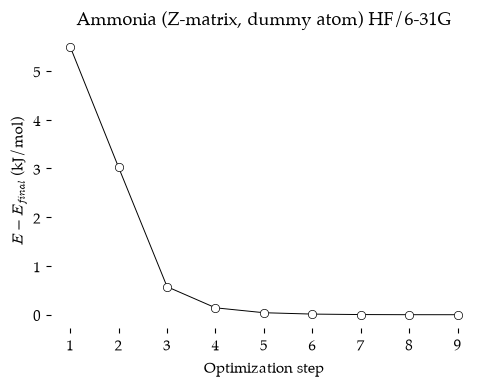

In [20]:
psi4.set_output_file("ammonia_zmat.out", False)

E_ammonia, hist_ammonia = psi4.optimize("hf/6-31g", molecule=ammonia, return_history=True)

print(f"Energy:       {E_ammonia:.8f} Hartree")
print(f"N-H lengths:  {bond_length(ammonia, 0, 1):.4f}  {bond_length(ammonia, 0, 2):.4f}",
      f" {bond_length(ammonia, 0, 3):.4f} Angstrom")
print(f"H-N-H angles: {bond_angle(ammonia, 1, 0, 2):.2f}  {bond_angle(ammonia, 1, 0, 3):.2f}",
      f" {bond_angle(ammonia, 2, 0, 3):.2f} degrees")

show_molecule(ammonia)
plot_history(hist_ammonia, "Ammonia (Z-matrix, dummy atom) HF/6-31G")

The dummy atom is **not** part of the calculation, so it does not appear in `ammonia.geometry()`. The real atoms are numbered from `0` in the order they appear: the nitrogen is atom `0` and the three hydrogens are atoms `1`, `2` and `3`.

We observe that the three bond lengths are all **exactly** the same (0.9913 &Aring;) and the three H&ndash;N&ndash;H angles are also **exactly** the same (116.12&deg;), as required by the *C<sub>3v</sub>* point group. The final energy is &minus;56.16552 Hartree. Compare these with the experimental structure of ammonia: N&ndash;H bond lengths of 1.012 &Aring; and H&ndash;N&ndash;H angles of 106.7&deg;. The bonds are 0.02 &Aring; too short, and the angles are 9.4&deg; too **large**. HF/6-31G has made ammonia much too **flat** (a planar molecule would have 120&deg; angles). This is a well-known **weakness** of basis sets without polarization functions. The lone pair on nitrogen needs *d* functions to be described properly. Try `"hf/6-31g(d,p)"` and see what happens.

Look at the energy plot. This optimization took **nine** steps, even though our starting structure was only 5.5 *kJ/mol* above the final structure (compare 38 *kJ/mol* for our squashed water). Flattening the ammonia pyramid changes the energy very little at this level of theory. On such a **shallow** energy surface, the forces are small and the optimizer creeps toward the bottom in many small steps.

Now look at the **output file**. Search for the energy at each step and then print the final geometry and variables.

In [21]:
search_file("ammonia_zmat.out", "@RHF Final Energy")

with open("ammonia_zmat.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Final optimized geometry" in line)
print("".join(lines[start:start + 14]))

   212:   @RHF Final Energy:   -56.16342868476478
   572:   @RHF Final Energy:   -56.16437121613898
   932:   @RHF Final Energy:   -56.16530263345749
  1292:   @RHF Final Energy:   -56.16546743706367
  1652:   @RHF Final Energy:   -56.16550575629938
  2011:   @RHF Final Energy:   -56.16551643178138
  2370:   @RHF Final Energy:   -56.16552011835756
  2729:   @RHF Final Energy:   -56.16552120553069
  3087:   @RHF Final Energy:   -56.16552132480459
    Final optimized geometry and variables:
    Molecular point group: cs
    Full point group: C3v

    Geometry (in Angstrom), charge = 0, multiplicity = 1:

    N            0.000000000000    -0.035132632301     0.000000000000
    H           -0.485703027065     0.162715032981    -0.841262320266
    H           -0.485703027065     0.162715032981     0.841262320266
    H            0.971406054130     0.162715032981     0.000000000000




Nine energies, one for each step, falling from &minus;56.16343 to &minus;56.16552 Hartree. Now look at the final geometry. *Psi4* did **not** give us back our *Z-matrix*. The dummy atom is not a real atom, so it was not moved during the optimization, and *Psi4* reports **Cartesian coordinates** instead. (*GAMESS* did the same thing with this *Z-matrix*.)

*Psi4* has also **rotated** the molecule. All three hydrogens have the same *y* value (0.163 &Aring;) and the nitrogen sits on the *y*-axis below them, so the *C<sub>3</sub>* axis now lies along *y*. One hydrogen lies in the *xy* plane (*z* = 0) and the other two are mirror images of each other at *z* = &plusmn;0.841 &Aring;. The *xy* plane is the **mirror plane** that *Psi4* uses for its *C<sub>s</sub>* calculation.

Without a *Z-matrix*, we cannot read the H&ndash;N&ndash;H angle from the output. (Remember that `a` was the X&ndash;N&ndash;H angle anyway.) We can use our `bond_angle()` function, as above, or ask *Psi4* to print all the angles to the output file.

In [22]:
ammonia.print_bond_angles()
search_file("ammonia_zmat.out", "Angle")

  3275:         Bond Angles (degrees)
  3277:         Angle 2-1-3:  116.120
  3278:         Angle 2-1-4:  116.120
  3279:         Angle 3-1-4:  116.120
  3280:         Angle 1-2-3:   31.940
  3281:         Angle 1-2-4:   31.940
  3282:         Angle 3-2-4:   60.000
  3283:         Angle 1-3-2:   31.940
  3284:         Angle 1-3-4:   31.940
  3285:         Angle 2-3-4:   60.000
  3286:         Angle 1-4-2:   31.940
  3287:         Angle 1-4-3:   31.940
  3288:         Angle 2-4-3:   60.000


## Comparing Results

In the table above, *Psi4* numbered the atoms from one: N is 1 and the hydrogens are 2, 3 and 4. The three angles with the nitrogen in the **middle** (2-1-3, 2-1-4 and 3-1-4) are the H&ndash;N&ndash;H bond angles, all 116.120&deg;. The 31.940&deg; angles are at the hydrogens in each N&ndash;H&ndash;H triangle. The 60.000&deg; angles are in the triangle made by the three hydrogens. It is an **equilateral** triangle, a nice confirmation of the *C<sub>3v</sub>* symmetry.

We have optimized water twice and ammonia once. Let us collect the results in a **table** alongside the experimental values. Experimental structures are from the [Computational Chemistry Comparison and Benchmark DataBase](https://cccbdb.nist.gov) (CCCBDB).

In [23]:
results = pd.DataFrame({
    "Molecule":   ["Water (Cartesian)", "Water (Z-matrix)", "Ammonia (Z-matrix)"],
    "Energy (Eh)": [E_water, E_water_z, E_ammonia],
    "Length (A)": [bond_length(water, 0, 1), bond_length(water_z, 0, 1), bond_length(ammonia, 0, 1)],
    "Angle (deg)": [bond_angle(water, 1, 0, 2), bond_angle(water_z, 0, 1, 2), bond_angle(ammonia, 1, 0, 2)],
    "Exp. length (A)": [0.958, 0.958, 1.012],
    "Exp. angle (deg)": [104.5, 104.5, 106.7],
    "Steps": [len(hist_water["energy"]), len(hist_water_z["energy"]), len(hist_ammonia["energy"])],
})

results.to_json("small_molecules_HF631G.json", orient="records", indent=2)
results.round(4)

,Molecule,Energy (Eh),Length (A),Angle (deg),Exp. length (A),Exp. angle (deg),Steps
0,Water (Cartesian),-75.9854,0.9496,111.5468,0.958,104.5,5
1,Water (Z-matrix),-75.9854,0.9497,111.5477,0.958,104.5,4
2,Ammonia (Z-matrix),-56.1655,0.9913,116.1202,1.012,106.7,9


| Line | Notes |
| :---- | :---- |
| `pd.DataFrame({...})` | Makes a *pandas* **table** from a dictionary. Each key is a column heading and each value is a list with one entry per row. |
| `results.to_json(...)` | Saves the table as a **JSON** file so that we can use the results later without recalculating them. |
| `results.round(4)` | Displays the table rounded to four decimal places. When a cell ends with a variable name, *Jupyter* displays it. |

The two water calculations agree with each other to four decimal places. The bond **lengths** are close to experiment, but slightly too short (0.950 vs 0.958 &Aring; for water and 0.991 vs 1.012 &Aring; for ammonia). The bond **angles** are much too large: by 7.0&deg; for water and by 9.4&deg; for ammonia. The two molecules also took different numbers of steps to optimize: water optimized in four or five steps, ammonia needed nine.

Even so, the **qualitative** picture is correct: water is bent and ammonia is pyramidal, as VSEPR theory predicts. Even the **trend** is right. In experiment, the H&ndash;N&ndash;H angle of ammonia (106.7&deg;) is larger than the H&ndash;O&ndash;H angle of water (104.5&deg;), because water has two lone pairs pushing its bonds together and ammonia has only one. HF/6-31G gets the same order (116.1&deg; vs 111.5&deg;), even though both numbers are too large. For many questions in organic chemistry, that is all we need. When we need **better numbers**, we know how to get them.

## Summary

We have explored using *Psi4* to **calculate** the structure and energy of some small molecules. We used **Cartesian coordinates** to describe the initial structure and let *Psi4* **detect** the symmetry point group for us. We used **internal coordinates** with the *Z-matrix*, using **variables** and **dummy atoms** to enforce symmetry exactly.

We have run *Psi4* from a *Jupyter* notebook using `psi4.geometry()` to build molecules and `psi4.optimize()` to find their lowest-energy structures. We have used *py3Dmol* to **look** at the starting and optimized structures, and we have **plotted** the energy at each step of each optimization.

We have **read the results** in two ways: directly as *Python* variables, and by **searching** the text output files. We have examined the output and determined that the results were as expected, with the limitations of a **low level of theory**.

Now go to the exercise below and explore *Psi4* for yourself.

## Exercise

### The Activity

**Build** the tetrahedral methane molecule. It belongs to the *T<sub>d</sub>* point group. Look to the ammonia *Z-matrix* with the dummy atom for inspiration, or use Cartesian coordinates. **Run** an HF/6-31G optimization on your computer. If you are successful, you will have accomplished the first four of our learning goals. If it was not successful, **try another way** to build the molecule. Errors are learning opportunities. Give yourself time to make lots of them.

- Check that *Psi4* reports the **full point group** as *T<sub>d</sub>*. What computational point group does it use?
- **Show** the starting and optimized structures with `show_molecule()`.
- **Plot** the energy at each step with `plot_history()`.
- What are the C&ndash;H bond lengths and H&ndash;C&ndash;H bond angles for methane? **Compare** them to the experimental values (1.087 &Aring; and 109.47&deg;).
- **Search** the output file for the energy at each step and the final geometry.

**Going further:** Use the optimized structures of methane, ammonia and water to calculate a single-point energy at a higher level of theory, for example `psi4.energy("hf/6-311++g(d,p)", molecule=methane)`. Then **optimize** each molecule at that higher level. How much does the energy change? How much does the structure change? Was the HF/6-31G structure a good **starting point**?

````{admonition} Hint: Cartesian coordinates for methane
:class: dropdown
A tetrahedron fits neatly inside a cube. Place carbon at the center of a cube and the four hydrogens on alternating corners.

```text
C    0.0   0.0   0.0
H    0.63  0.63  0.63
H   -0.63 -0.63  0.63
H   -0.63  0.63 -0.63
H    0.63 -0.63 -0.63
```

What C&ndash;H bond length does this give?
````

````{admonition} Hint: a Z-matrix for methane
:class: dropdown
Methane does not need a dummy atom. Place one hydrogen on the axis, and arrange the other three around it like the hydrogens of ammonia. For exact *T<sub>d</sub>* symmetry, the H&ndash;C&ndash;H angle must be exactly 109.4712206&deg;, not 109.5&deg;.

```text
C
H  1  r
H  1  r  2  a
H  1  r  2  a  3   120.0
H  1  r  2  a  3  -120.0

r = 1.09
a = 109.4712206
```
````

### The Report

**Create** a ONE PAGE document summarizing your **results** for methane, ammonia and water in a table: energies, bond lengths and bond angles at HF/6-31G, alongside the experimental values. Do the results fit with what you know about VSEPR theory? Which molecule did HF/6-31G describe **best**? Which did it describe **worst**? Why might that be?

| Molecule | Bond length (&Aring;) | Bond angle (&deg;) | HF/6-31G energy (Hartree) | Exp. length (&Aring;) | Exp. angle (&deg;) |
| :------- | :---- | :---- | :---- | :---- | :---- |
| Methane  |       |       |       | 1.087  | 109.47 |
| Ammonia  |       |       |       | 1.012  | 106.7  |
| Water    |       |       |       | 0.958  | 104.5  |

**Comment** on the difference between describing a molecule with Cartesian coordinates and with a *Z-matrix*. Which was easier to write? Which made it easier to **control** symmetry? Which made it easier to **read** the results?

Include an appendix with the *Python* code that you used to build each molecule and run each calculation. (Please do not include any output files &ndash; there will be no trees left!) Use a fixed-width font.